# Task 1: Student Score Prediction

📝 Problem Statement
In this task, I build a regression model to predict a student's **exam score** (`Exam_Score`) from performance-related factors, starting with the number of **hours studied**. This is a regression problem, where the goal is to predict a continuous numeric value.

The dataset is sourced from Kaggle: **Student Performance Factors** (6,607 students). It includes study habits, attendance, sleep, previous scores, tutoring, family and school factors.


## 🧠 Approach: 6-Step Machine Learning Framework

### 1. Problem

Predict a student's exam score from the factors that may influence it. This type of prediction can help educators identify at-risk students and take early action to support them.

### 2. Data

The dataset is from Kaggle: Student Performance Factors.

Key columns include:

* `Exam_Score` (target)

* `Hours_Studied`, `Attendance`, `Sleep_Hours`, `Previous_Scores`, `Tutoring_Sessions`, `Physical_Activity`

* Categorical factors such as `Parental_Involvement`, `Access_to_Resources`, `Motivation_Level`, `Internet_Access`, `Gender`, etc.

### 3. Evaluation

Since this is a regression problem, model performance is evaluated using:

* Mean Squared Error (MSE)

* Mean Absolute Error (MAE)

* R² Score (Coefficient of Determination)

* Visualization of predictions against the actual data

### 4. Features

* The model uses `Hours_Studied` as the input feature to measure how much of the variation in exam scores study time alone explains.

* Columns with missing values that are not needed (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`) are dropped during cleaning.

### 5. Tools & Framework

* Frame the problem – Regression with numeric output

* Explore & preprocess the data – Clean and visualize

* Choose a model – Linear Regression

* Train the model – Fit on the training data

* Evaluate the model – Regression metrics and plots

* Improve – Compare against Polynomial Regression (degree 2)

Libraries used:

* pandas, numpy for data handling

* matplotlib, seaborn for visualization

* scikit-learn for modeling and evaluation


# Get Our Workspace Ready

* Import all tools needed

In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning models and tools
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 2. Data Exploration & Cleaning

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ML intern/Task1/StudentPerformanceFactors.csv')

In [ ]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:
# Understandin the dataset
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [ ]:
df_clean = df.drop(columns=['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home'])
df_clean.shape

(6607, 17)

In [ ]:
x = df_clean[["Hours_Studied"]]
y = df_clean["Exam_Score"]

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

### 3. Building the Model

In [ ]:
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_predict = model.predict(x_test)

### 4. Evaluation

In [ ]:
print("mean squared error= ", mean_squared_error(y_test,y_predict))
print("r2 score= ", r2_score(y_test,y_predict))

mean squared error=  10.85592128879332
r2 score=  0.2319868674542106


###5. Data Visualization

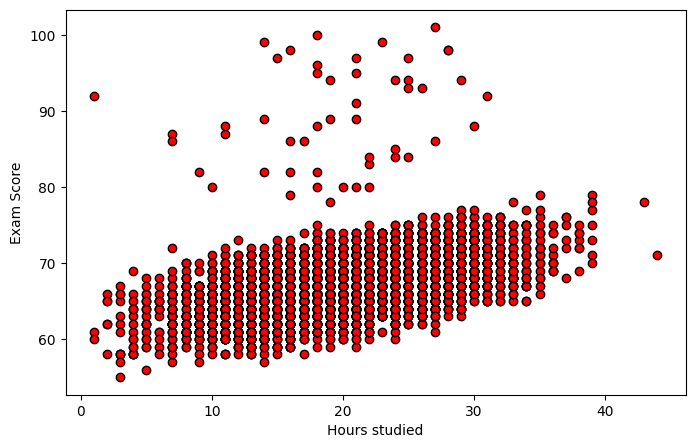

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(x, y , color='red', edgecolor='black')
plt.xlabel("Hours studied")
plt.ylabel("Exam Score")
plt.show()

Text(0.5, 1.0, 'Actual vs Predicted')

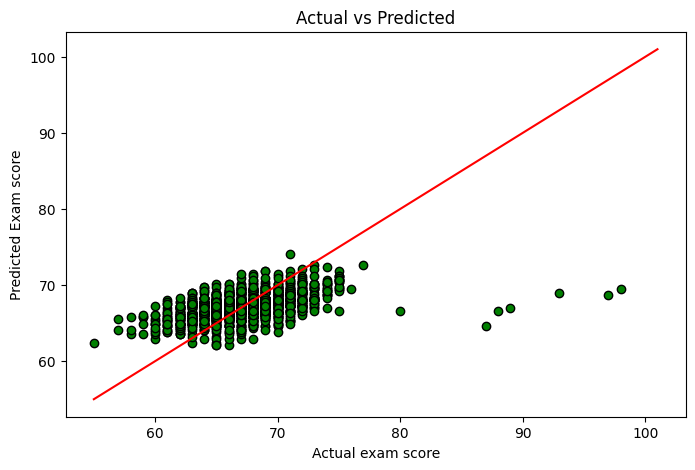

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_predict, color="green", edgecolor="black")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r')
plt.xlabel("Actual exam score")
plt.ylabel("Predicted Exam score")
plt.title("Actual vs Predicted")

# Bonus Section:

Try Polynoimal Regression and compare performance

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
poly = PolynomialFeatures(degree=2)
x_poly_train =  poly.fit_transform(x_train)
x_poly_test = poly.transform(x_test)

In [ ]:
poly_model = LinearRegression()
poly_model.fit(x_poly_train, y_train)
y_pred_poly = poly_model.predict(x_poly_test)

In [ ]:
# Performance Metrics
print(" Linear Regression:")
print("MSE: ", mean_squared_error(y_test, y_predict))
print("R2 Score: ", r2_score(y_test, y_predict))

print("Polynoimal Regression: ")
print("MSE: ", mean_squared_error(y_test, y_pred_poly))
print("R2 Score: ", r2_score(y_test, y_pred_poly))

 Linear Regression:
MSE:  10.85592128879332
R2 Score:  0.2319868674542106
Polynoimal Regression: 
MSE:  10.84498813570501
R2 Score:  0.23276034442853466


# Comparing Visualization between Linear and Polynoimal Regression

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


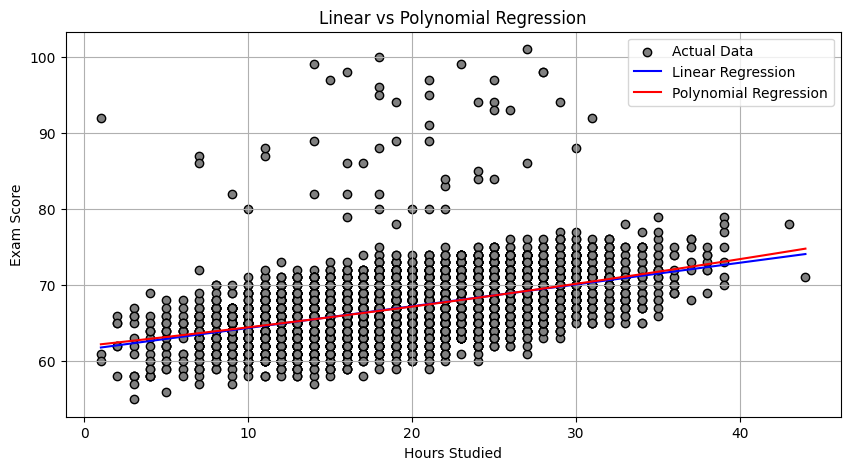

In [ ]:
plt.figure(figsize=(10, 5))

# Scatter the original data points
plt.scatter(x, y, color='grey', edgecolors='black', label='Actual Data')

# Create a smooth range of input values for plotting
x_range = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
x_range_df = pd.DataFrame(x_range, columns=["Hours_Studied"])

# Make predictions
y_linear_plot = model.predict(x_range_df)  # OK with feature names
y_poly_plot = poly_model.predict(poly.transform(x_range_df.values))  # FIX: remove feature names

# Plot linear regression line
plt.plot(x_range, y_linear_plot, color='blue', label='Linear Regression')

# Plot polynomial regression curve
plt.plot(x_range, y_poly_plot, color='red', label='Polynomial Regression')

# Labeling
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()
